# 02 · Customer Segmentation (Clustering)

**Goal:** group customers into homogeneous profiles using only their characteristics,
then interpret each profile.

⚠️ **The target `Churn` is never used as an input of the clustering.** It is only used
*after* the segmentation, to describe the churn rate of each profile.

| Step | Content |
| --- | --- |
| 1 | Select & scale the clustering features |
| 2 | K-Means: Elbow method + Silhouette score → choose *k* |
| 3 | Final K-Means model & evaluation (Silhouette, Davies-Bouldin, Calinski-Harabasz) |
| 4 | Alternative algorithms: Agglomerative & DBSCAN |
| 5 | PCA visualisation |
| 6 | Profile interpretation |
| 7 | Save the model & log to MLflow |

## Setup
This notebook is **self-contained**: it reloads the raw CSV and redefines the cleaning,
feature-engineering and preprocessing steps (explained in detail in notebook 01), so it
can be run on its own.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DATA = ROOT / "data" / "raw" / "wa-fn-usec-telco-customer.csv"
MODELS_DIR = ROOT / "models"
MLFLOW_URI = f"sqlite:///{ROOT / 'mlflow.db'}"

RANDOM_STATE = 42
TARGET = "Churn"
ID_COLUMN = "customerID"

### Cleaning & feature engineering
- `clean_raw`: convert `TotalCharges` to numeric (blank → NaN) and drop duplicated profiles.
- `add_features`: row-wise engineered features (no learned statistic → no leakage).

In [2]:
SERVICE_COLUMNS = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                   "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]


def clean_raw(df):
    df = df.copy()
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
    return df.drop_duplicates(subset=[c for c in df.columns if c != ID_COLUMN]).reset_index(drop=True)


def add_features(df):
    df = df.copy()
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
    df["num_services"] = (df[SERVICE_COLUMNS] == "Yes").sum(axis=1) + (df["InternetService"] != "No")
    df["avg_monthly_spend"] = np.where(df["tenure"] > 0,
                                       df["TotalCharges"] / df["tenure"].replace(0, np.nan),
                                       df["MonthlyCharges"])
    df["charges_per_service"] = df["MonthlyCharges"] / df["num_services"].clip(lower=1)
    df["is_month_to_month"] = (df["Contract"] == "Month-to-month").astype(int)
    df["auto_payment"] = df["PaymentMethod"].str.contains("automatic").astype(int)
    df["has_family"] = ((df["Partner"] == "Yes") | (df["Dependents"] == "Yes")).astype(int)
    df["is_new_customer"] = (df["tenure"] <= 6).astype(int)
    df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 60, 72],
                                labels=["0-12", "13-24", "25-48", "49-60", "61-72"]).astype(str)
    return df

### Preprocessing
Numeric → median imputation + standardization; binary → unchanged;
categorical → most-frequent imputation + one-hot encoding.

In [3]:
RAW_NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges"]
RAW_BINARY = ["SeniorCitizen"]
RAW_CATEGORICAL = ["gender", "Partner", "Dependents", "PhoneService", "MultipleLines",
                   "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                   "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
                   "PaperlessBilling", "PaymentMethod"]

NUMERIC_FEATURES = RAW_NUMERIC + ["num_services", "avg_monthly_spend", "charges_per_service"]
BINARY_FEATURES = RAW_BINARY + ["is_month_to_month", "auto_payment", "has_family", "is_new_customer"]
CATEGORICAL_FEATURES = RAW_CATEGORICAL + ["tenure_group"]

# Subset used for segmentation (no target!)
CLUSTER_NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges", "num_services"]
CLUSTER_BINARY = ["is_month_to_month", "auto_payment", "has_family", "SeniorCitizen"]
CLUSTER_CATEGORICAL = ["InternetService"]


def make_preprocessor(numeric=NUMERIC_FEATURES, binary=BINARY_FEATURES, categorical=CATEGORICAL_FEATURES):
    numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                             ("scaler", StandardScaler())])
    categorical_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                 ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary",
                                                          sparse_output=False))])
    return ColumnTransformer([("num", numeric_pipe, numeric),
                              ("bin", "passthrough", binary),
                              ("cat", categorical_pipe, categorical)],
                             verbose_feature_names_out=False)

### Load data

In [4]:
df = clean_raw(pd.read_csv(RAW_DATA))
print("Dataset:", df.shape)

Dataset: (7021, 21)


In [5]:
import json

import cloudpickle
import mlflow
import mlflow.sklearn
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.neighbors import NearestNeighbors

## 1. Clustering features
We segment customers on **behaviour, contract and spending** — the variables that
describe *who the customer is for the business*:

- numeric: `tenure`, `MonthlyCharges`, `TotalCharges`, `num_services`
- binary: `is_month_to_month`, `auto_payment`, `has_family`, `SeniorCitizen`
- categorical: `InternetService` (DSL / Fiber optic / No)

Using all ~50 one-hot columns would drown the structure in noise (many near-redundant
Yes/No service columns), so a compact, meaningful subset is preferred. Numeric features
are standardized so that no variable dominates the Euclidean distance.

In [6]:
df = add_features(df)
cluster_cols = CLUSTER_NUMERIC + CLUSTER_BINARY + CLUSTER_CATEGORICAL

X_raw = df[cluster_cols]
assert TARGET not in X_raw.columns, "Churn must not be used for clustering"

preprocessor = make_preprocessor(CLUSTER_NUMERIC, CLUSTER_BINARY, CLUSTER_CATEGORICAL)
X = preprocessor.fit_transform(X_raw)
feature_names = preprocessor.get_feature_names_out()
print("Clustering matrix:", X.shape)
pd.DataFrame(X, columns=feature_names).head()

Clustering matrix: (7021, 11)


,tenure,MonthlyCharges,TotalCharges,num_services,is_month_to_month,auto_payment,has_family,SeniorCitizen,InternetService_DSL,InternetService_Fiber optic,InternetService_No
0,-1.282728,-1.164135,-0.997334,-0.932578,1.0,0.0,1.0,0.0,1.0,0.0,0.0
1,0.062387,-0.262811,-0.176352,-0.067062,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,-1.241967,-0.365914,-0.962766,-0.067062,1.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.510759,-0.750058,-0.197874,-0.067062,0.0,1.0,0.0,0.0,1.0,0.0,0.0
4,-1.241967,0.194503,-0.943562,-0.932578,1.0,0.0,0.0,0.0,0.0,1.0,0.0


## 2. Choosing the number of clusters
For *k* = 2…10 we compute:
- **Inertia** (within-cluster sum of squares) → *Elbow method*: we look for the point where
  adding clusters stops reducing inertia much.
- **Silhouette score** (−1…1, higher = better separated clusters).
- **Davies-Bouldin** (lower = better) and **Calinski-Harabasz** (higher = better).

In [7]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    rows.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": silhouette_score(X, km.labels_),
        "davies_bouldin": davies_bouldin_score(X, km.labels_),
        "calinski_harabasz": calinski_harabasz_score(X, km.labels_),
    })
k_scores = pd.DataFrame(rows).set_index("k")
k_scores.round(3)

,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,22834.220,0.353,1.118,4893.392
3,16737.937,0.328,1.166,4615.402
4,14110.347,0.321,1.254,4084.954
5,12221.563,0.304,1.232,3807.771
6,10769.842,0.311,1.171,3645.454
7,9597.985,0.301,1.190,3551.034
8,8850.133,0.298,1.176,3385.127
9,8364.903,0.279,1.281,3184.221
10,7912.821,0.276,1.336,3036.190


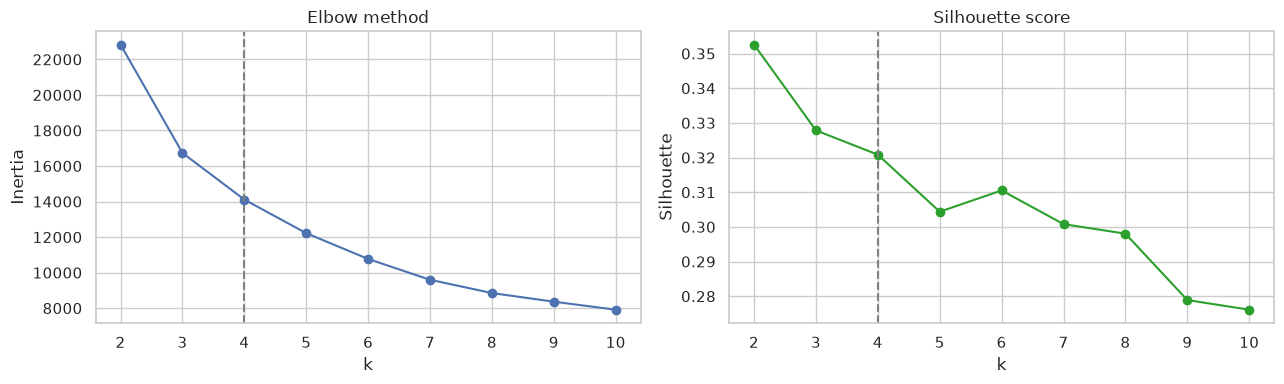

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(k_scores.index, k_scores["inertia"], marker="o")
axes[0].set(title="Elbow method", xlabel="k", ylabel="Inertia")
axes[1].plot(k_scores.index, k_scores["silhouette"], marker="o", color="tab:green")
axes[1].set(title="Silhouette score", xlabel="k", ylabel="Silhouette")
for ax in axes:
    ax.axvline(4, ls="--", color="grey")
plt.tight_layout()
elbow_fig = fig
plt.show()

**Choice of k = 4**
- The elbow curve bends around *k* = 3–4: after 4, each extra cluster brings a much
  smaller reduction of inertia.
- The silhouette is highest at *k* = 2 (0.35), but *k* = 4 stays very close (0.32);
  *k* = 2 only splits "customers with internet" from "without", which is too coarse.
- With *k* = 4 we get four clearly distinct and actionable business profiles (see §6).

We therefore keep **k = 4**, a good trade-off between statistical quality and interpretability.

In [9]:
N_CLUSTERS = 4

## 3. Final K-Means model

In [10]:
kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=RANDOM_STATE)
labels_km = kmeans.fit_predict(X)

def cluster_metrics(X, labels):
    return {
        "n_clusters": len(set(labels)) - (1 if -1 in labels else 0),
        "silhouette": silhouette_score(X, labels),
        "davies_bouldin": davies_bouldin_score(X, labels),
        "calinski_harabasz": calinski_harabasz_score(X, labels),
    }

km_metrics = cluster_metrics(X, labels_km)
print(pd.Series(km_metrics).round(3))
print("\nCluster sizes:\n", pd.Series(labels_km).value_counts().sort_index())

n_clusters              4.000
silhouette              0.321
davies_bouldin          1.254
calinski_harabasz    4084.954
dtype: float64

Cluster sizes:
 0    1526
1    2016
2    1682
3    1797
Name: count, dtype: int64


## 4. Alternative algorithms
### 4.1 Agglomerative clustering (Ward linkage)
Hierarchical clustering that merges the closest groups step by step, minimising the
within-cluster variance (same objective as K-Means, but deterministic and not limited to
spherical initialisations).

In [11]:
agglo = AgglomerativeClustering(n_clusters=N_CLUSTERS, linkage="ward")
labels_agg = agglo.fit_predict(X)
agg_metrics = cluster_metrics(X, labels_agg)
print(pd.Series(agg_metrics).round(3))
print("\nCluster sizes:\n", pd.Series(labels_agg).value_counts().sort_index())

n_clusters              4.000
silhouette              0.296
davies_bouldin          1.257
calinski_harabasz    3614.420
dtype: float64

Cluster sizes:
 0    2183
1    1916
2    1512
3    1410
Name: count, dtype: int64


### 4.2 DBSCAN
Density-based: finds dense regions and labels isolated points as noise (`-1`); the number
of clusters is not given in advance. `eps` is chosen with the **k-distance plot** (distance
of each point to its 10th neighbour, sorted): the "knee" of the curve is a good `eps` candidate.

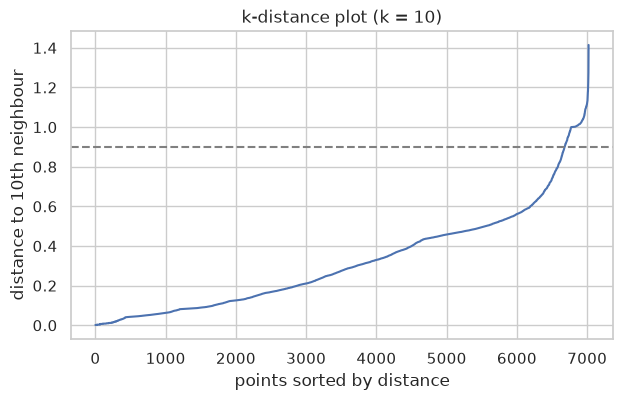

In [12]:
MIN_SAMPLES = 10
distances = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X).kneighbors(X)[0][:, -1]
plt.figure(figsize=(7, 4))
plt.plot(np.sort(distances))
plt.axhline(0.9, ls="--", color="grey")
plt.title(f"k-distance plot (k = {MIN_SAMPLES})")
plt.xlabel("points sorted by distance")
plt.ylabel(f"distance to {MIN_SAMPLES}th neighbour")
plt.show()

In [13]:
dbscan_rows = []
for eps in [0.5, 0.7, 0.9, 1.1, 1.5]:
    labels = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X)
    mask = labels != -1
    n_clusters = len(set(labels[mask]))
    row = {"eps": eps, "n_clusters": n_clusters, "noise_points": int((~mask).sum())}
    if n_clusters > 1:
        row["silhouette (non-noise)"] = silhouette_score(X[mask], labels[mask])
    dbscan_rows.append(row)
pd.DataFrame(dbscan_rows).round(3)

,eps,n_clusters,noise_points,silhouette (non-noise)
0,0.5,36,813,0.164
1,0.7,38,278,0.159
2,0.9,39,119,0.161
3,1.1,3,0,0.230
4,1.5,1,0,NaN


In [14]:
labels_db = DBSCAN(eps=0.9, min_samples=MIN_SAMPLES).fit_predict(X)
mask_db = labels_db != -1
db_metrics = cluster_metrics(X[mask_db], labels_db[mask_db])
db_metrics["noise_points"] = int((~mask_db).sum())
print(pd.Series(db_metrics).round(3))

n_clusters            39.000
silhouette             0.161
davies_bouldin         1.796
calinski_harabasz    598.190
noise_points         119.000
dtype: float64


DBSCAN is not well suited here: the data is mostly made of binary / one-hot variables,
which creates many small, dense "grid" groups of identical profiles. Around the knee
(`eps` ≈ 0.9) it produces dozens of micro-clusters with a low silhouette; with a larger
`eps` everything merges into a few groups that just follow `InternetService`.

### 4.3 Comparison

In [15]:
comparison = pd.DataFrame({
    "K-Means (k=4)": km_metrics,
    "Agglomerative Ward (k=4)": agg_metrics,
    "DBSCAN (eps=0.9, without noise)": db_metrics,
}).T
comparison.round(3)

,n_clusters,silhouette,davies_bouldin,calinski_harabasz,noise_points
K-Means (k=4),4.0,0.321,1.254,4084.954,NaN
Agglomerative Ward (k=4),4.0,0.296,1.257,3614.420,NaN
"DBSCAN (eps=0.9, without noise)",39.0,0.161,1.796,598.190,119.0


In [16]:
pd.crosstab(labels_km, labels_agg, rownames=["K-Means"], colnames=["Agglomerative"])

Agglomerative,0,1,2,3
K-Means,,,,
0,1,0,1512,13
1,1854,143,0,19
2,304,0,0,1378
3,24,1773,0,0


K-Means has the best silhouette / Davies-Bouldin / Calinski-Harabasz trade-off.
The crosstab shows that Agglomerative finds largely the same groups, which confirms the
segmentation is stable. **K-Means is kept** — it can also assign new customers to a
cluster with `predict`, which is required by the Streamlit app.

## 5. PCA visualisation
PCA projects the 11 scaled features onto 2 axes that keep the most variance, so the
clusters can be plotted.

Explained variance: [0.564 0.211] → total 0.775


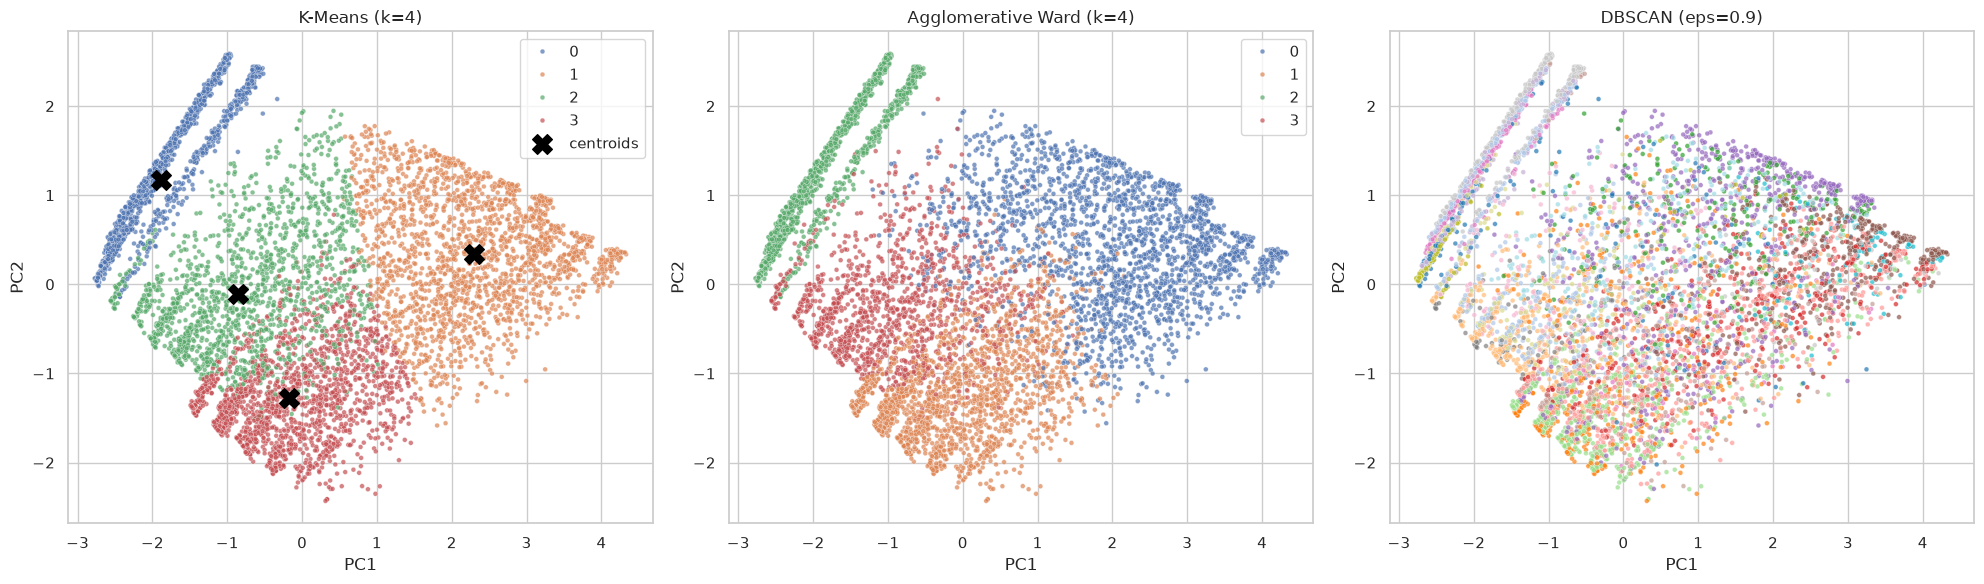

In [17]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
print("Explained variance:", pca.explained_variance_ratio_.round(3),
      "→ total", pca.explained_variance_ratio_.sum().round(3))

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, labels, title in [
    (axes[0], labels_km, "K-Means (k=4)"),
    (axes[1], labels_agg, "Agglomerative Ward (k=4)"),
    (axes[2], labels_db, "DBSCAN (eps=0.9)"),
]:
    palette = "tab20" if len(set(labels)) > 10 else "deep"
    sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels, palette=palette, s=12,
                    alpha=0.7, ax=ax, legend=len(set(labels)) <= 10)
    ax.set(title=title, xlabel="PC1", ylabel="PC2")
centers = pca.transform(kmeans.cluster_centers_)
axes[0].scatter(centers[:, 0], centers[:, 1], c="black", marker="X", s=200, label="centroids")
axes[0].legend()
plt.tight_layout()
pca_fig = fig
plt.show()

In [18]:
loadings = pd.DataFrame(pca.components_.T, index=feature_names, columns=["PC1", "PC2"])
loadings.sort_values("PC1").round(2)

,PC1,PC2
InternetService_No,-0.13,0.22
is_month_to_month,-0.10,-0.31
InternetService_DSL,-0.01,0.06
SeniorCitizen,0.03,-0.07
has_family,0.07,0.15
auto_payment,0.08,0.17
InternetService_Fiber optic,0.14,-0.28
tenure,0.41,0.61
MonthlyCharges,0.47,-0.51
num_services,0.52,-0.21


PC1 is driven by total charges, number of services, monthly charges and tenure (customer
*value / engagement*); PC2 opposes long-tenure customers to those with high monthly
charges, fiber optic and month-to-month contracts (*risk* axis).
K-Means clusters are well separated in this plane.

## 6. Profile interpretation
Mean of the main characteristics per cluster. `Churn` is added **only now**, to describe
each profile — it was not used to build the clusters.

In [19]:
df["cluster"] = labels_km
df["churn_flag"] = (df[TARGET] == "Yes").astype(int)

profile = df.groupby("cluster").agg(
    customers=("cluster", "size"),
    tenure=("tenure", "mean"),
    monthly_charges=("MonthlyCharges", "mean"),
    total_charges=("TotalCharges", "mean"),
    num_services=("num_services", "mean"),
    month_to_month=("is_month_to_month", "mean"),
    auto_payment=("auto_payment", "mean"),
    has_family=("has_family", "mean"),
    senior=("SeniorCitizen", "mean"),
    churn_rate=("churn_flag", "mean"),
)
profile["share"] = profile["customers"] / len(df)
internet = pd.crosstab(df["cluster"], df["InternetService"], normalize="index")
profile.join(internet.add_prefix("internet_")).round(2)

,customers,tenure,monthly_charges,total_charges,num_services,month_to_month,auto_payment,has_family,senior,churn_rate,share,internet_DSL,internet_Fiber optic,internet_No
cluster,,,,,,,,,,,,,,
0,1526,30.89,21.13,674.40,1.23,0.34,0.44,0.57,0.04,0.07,0.22,0.01,0.00,0.99
1,2016,59.52,91.24,5418.42,6.72,0.22,0.65,0.73,0.20,0.14,0.29,0.36,0.64,0.00
2,1682,20.28,51.55,1069.74,3.77,0.70,0.36,0.45,0.11,0.25,0.24,1.00,0.00,0.00
3,1797,14.88,84.82,1287.04,4.13,0.95,0.27,0.38,0.28,0.57,0.26,0.00,1.00,0.00


Profiles are named automatically from their characteristics (so the names stay correct
even if the cluster ids change):

In [20]:
def name_cluster(row, internet_row):
    if internet_row["No"] > 0.5:
        return "Basic phone-only"
    if row["tenure"] == profile["tenure"].max():
        return "Loyal premium"
    if row["churn_rate"] == profile["churn_rate"].max():
        return "New fiber, at risk"
    return "Mid-value DSL"

cluster_names = {int(c): name_cluster(profile.loc[c], internet.loc[c]) for c in profile.index}
profile["profile"] = profile.index.map(cluster_names)
profile[["profile", "customers", "share", "tenure", "monthly_charges", "num_services",
         "month_to_month", "churn_rate"]].round(2)

,profile,customers,share,tenure,monthly_charges,num_services,month_to_month,churn_rate
cluster,,,,,,,,
0,Basic phone-only,1526,0.22,30.89,21.13,1.23,0.34,0.07
1,Loyal premium,2016,0.29,59.52,91.24,6.72,0.22,0.14
2,Mid-value DSL,1682,0.24,20.28,51.55,3.77,0.70,0.25
3,"New fiber, at risk",1797,0.26,14.88,84.82,4.13,0.95,0.57


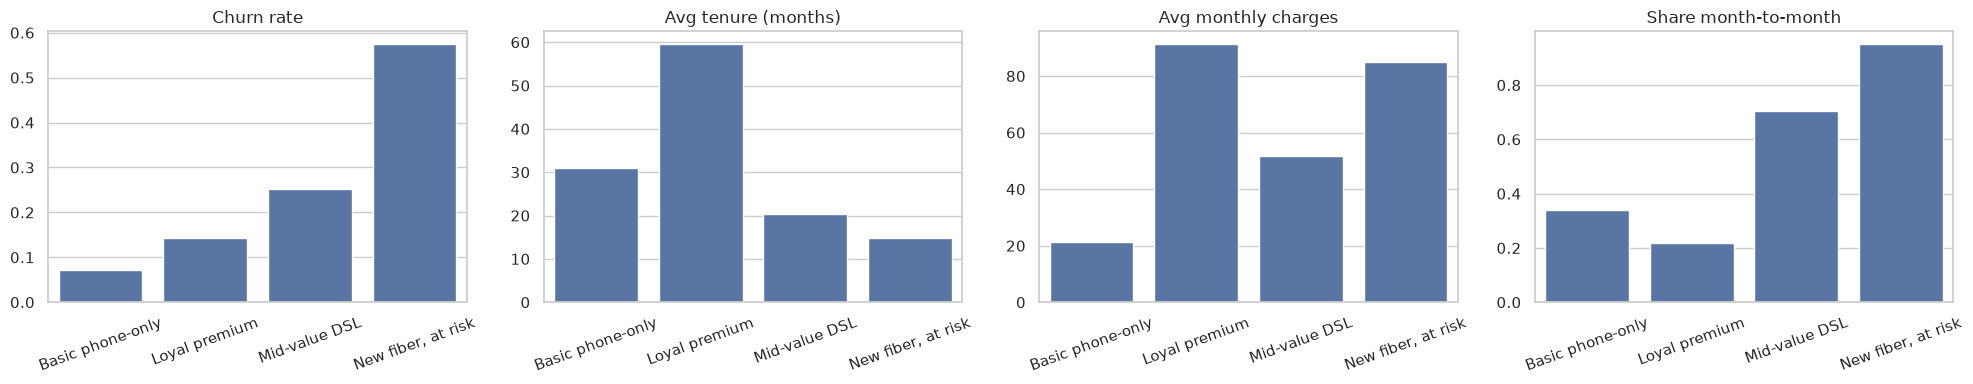

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
order = profile.sort_values("churn_rate").index
names = [cluster_names[c] for c in order]
for ax, col, title in [
    (axes[0], "churn_rate", "Churn rate"),
    (axes[1], "tenure", "Avg tenure (months)"),
    (axes[2], "monthly_charges", "Avg monthly charges"),
    (axes[3], "month_to_month", "Share month-to-month"),
]:
    sns.barplot(x=names, y=profile.loc[order, col].values, ax=ax)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
profile_fig = fig
plt.show()

### Interpretation

| Profile | Description | Churn | Business action |
| --- | --- | --- | --- |
| **Basic phone-only** | No internet, ~1 service, very low bill (~21/month), medium tenure | very low (~7 %) | low value but stable; upsell internet carefully |
| **Loyal premium** | ~5 years of tenure, many services, highest bill (~91/month), mostly 1–2 year contracts, auto-payment, families | low (~14 %) | best customers: retain & reward (loyalty program) |
| **Mid-value DSL** | DSL internet, ~20 months tenure, medium bill (~52/month), mostly month-to-month (70 %) | medium (~25 %) | push longer contracts and add-on services |
| **New fiber, at risk** | Fiber optic, new customers (~15 months), high bill (~85/month), almost all month-to-month, manual payment | very high (~57 %) | **priority retention target**: contract incentives, onboarding, price/quality review of fiber |

Even though `Churn` was never used, the segmentation separates customers with very
different churn rates (from ~7 % to ~57 %). This suggests the cluster could be a useful
feature for the churn classifier — tested in notebook 04.

## 7. Save the clustering model & log to MLflow
The saved object is a full pipeline **raw customer → feature engineering → scaling →
K-Means**, so the Streamlit app can assign a cluster to a new customer directly.
It is fitted on the cleaned dataset; since clustering is unsupervised and never sees
`Churn`, this does not leak the target.

In [22]:
def make_cluster_pipeline(n_clusters=N_CLUSTERS):
    return Pipeline([
        ("features", FunctionTransformer(add_features)),
        ("preprocess", make_preprocessor(CLUSTER_NUMERIC, CLUSTER_BINARY, CLUSTER_CATEGORICAL)),
        ("kmeans", KMeans(n_clusters=n_clusters, n_init=10, random_state=RANDOM_STATE)),
    ])


X_customers = df[pd.read_csv(RAW_DATA, nrows=1).columns.drop([ID_COLUMN, TARGET])]
cluster_pipeline = make_cluster_pipeline(N_CLUSTERS).fit(X_customers)
assert (cluster_pipeline.predict(X_customers) == labels_km).all()   # same clusters as above

MODELS_DIR.mkdir(exist_ok=True)
with open(MODELS_DIR / "cluster_pipeline.pkl", "wb") as f:
    cloudpickle.dump(cluster_pipeline, f)
(MODELS_DIR / "cluster_profiles.json").write_text(json.dumps({
    str(c): {"name": cluster_names[c], "churn_rate": round(float(profile.loc[c, "churn_rate"]), 3)}
    for c in profile.index}, indent=2))
print("Saved models/cluster_pipeline.pkl and models/cluster_profiles.json")

Saved models/cluster_pipeline.pkl and models/cluster_profiles.json


Log the clustering experiments to MLflow (parameters, metrics, figures, model).

In [23]:
import logging
logging.getLogger("mlflow").setLevel(logging.ERROR)

mlflow.set_tracking_uri(MLFLOW_URI)
if mlflow.get_experiment_by_name("tele-cluster-clustering") is None:
    mlflow.create_experiment("tele-cluster-clustering",
                             artifact_location=(ROOT / "mlruns" / "tele-cluster-clustering").as_uri())
mlflow.set_experiment("tele-cluster-clustering")

with mlflow.start_run(run_name=f"kmeans_k{N_CLUSTERS}"):
    mlflow.log_params({"algorithm": "KMeans", "n_clusters": N_CLUSTERS, "n_init": 10,
                       "random_state": RANDOM_STATE, "features": ",".join(cluster_cols),
                       "prep__scaler": "StandardScaler", "prep__encoder": "OneHotEncoder"})
    mlflow.log_metrics({k: float(v) for k, v in km_metrics.items()})
    mlflow.log_figure(elbow_fig, "elbow_silhouette.png")
    mlflow.log_figure(pca_fig, "pca_clusters.png")
    mlflow.log_figure(profile_fig, "cluster_profiles.png")
    mlflow.log_text(profile.round(3).to_csv(), "cluster_profiles.csv")
    mlflow.sklearn.log_model(cluster_pipeline, name="model", serialization_format="cloudpickle",
                             input_example=X_customers.head(3))

for name, algo, metrics in [("agglomerative_k4", "AgglomerativeClustering", agg_metrics),
                            ("dbscan_eps0.9", "DBSCAN", db_metrics)]:
    with mlflow.start_run(run_name=name):
        mlflow.log_param("algorithm", algo)
        mlflow.log_metrics({k: float(v) for k, v in metrics.items()})
print("Logged to MLflow experiment 'tele-cluster-clustering'")

Logged to MLflow experiment 'tele-cluster-clustering'


## Summary
- Clustering on 11 scaled features describing behaviour, contract and spending — **no churn**.
- Elbow + Silhouette → **k = 4** (silhouette ≈ 0.32), confirmed by Agglomerative clustering;
  DBSCAN is not adapted to this mostly-binary data.
- 4 interpretable profiles with churn rates from ~7 % to ~57 %: *Basic phone-only*,
  *Loyal premium*, *Mid-value DSL*, *New fiber at risk*.
- The clustering pipeline is saved in `models/` (e.g. for the Streamlit app).